# Analisis Jaringan Sungai dan Ordo Strahler — Sub-DAS Gede–Pangrango

Notebook ini melakukan analisis hidrologi **sepenuhnya berbasis DEM** (`DEM_Gede_Pangrango_Clip.tif`) untuk:

1. Membangun jaringan sungai dari DEM (bukan data sungai yang sudah ada).
2. Mengklasifikasikan orde sungai dengan metode **Strahler** yang benar.
3. Mendelineasi batas Sub-DAS dari titik outlet yang dipilih pengguna.
4. Menghasilkan peta akhir profesional (PNG 400 dpi + PDF) beserta data vektor.




## TAHAP 1 — Environment Check

Memeriksa versi Python dan seluruh library yang dibutuhkan. Notebook akan **berhenti dengan pesan instalasi yang jelas** apabila ada library yang belum terpasang, alih-alih gagal di tengah jalan dengan traceback yang membingungkan.

In [20]:

import sys
import importlib
import subprocess


print(f"\nPython version : {sys.version}")
print(f"Python executable: {sys.executable}")

if sys.version_info < (3, 9):
    raise RuntimeError(
        "Notebook ini membutuhkan Python >= 3.9 (direkomendasikan 3.11). "
        f"Terdeteksi: {sys.version_info.major}.{sys.version_info.minor}"
    )

# (module_import_name, pip_install_name)
REQUIRED_LIBS = [
    ("rasterio", "rasterio"),
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("geopandas", "geopandas"),
    ("shapely", "shapely"),
    ("pyproj", "pyproj"),
    ("matplotlib", "matplotlib"),
    ("scipy", "scipy"),
    ("whitebox", "whitebox"),
    ("networkx", "networkx"),
    ("matplotlib_scalebar", "matplotlib-scalebar"),
]

missing = []
versions = {}
for mod_name, pip_name in REQUIRED_LIBS:
    try:
        mod = importlib.import_module(mod_name)
        ver = getattr(mod, "__version__", "unknown")
        versions[mod_name] = ver
        print(f"  [OK] {mod_name:22s} versi {ver}")
    except ImportError:
        missing.append(pip_name)
        print(f"  [MISSING] {mod_name}")

if missing:
    pip_cmd = "pip install " + " ".join(sorted(set(missing)))
    print("\n" + "=" * 70)
    print("LIBRARY BELUM LENGKAP — INSTALASI DIPERLUKAN")
    print("=" * 70)
    print("Jalankan perintah berikut di terminal / Anaconda Prompt, lalu")
    print("restart kernel Jupyter dan jalankan ulang notebook dari awal:\n")
    print(f"    {pip_cmd}\n")
    print("Atau install semuanya sekaligus dari requirements.txt:")
    print("    pip install -r requirements.txt")
    raise ImportError(f"Library berikut belum terpasang: {missing}")

print("\nSemua library wajib tersedia.")



Python version : 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Python executable: C:\Users\Yusufalqodri\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
  [OK] rasterio               versi 1.4.4
  [OK] numpy                  versi 2.4.4
  [OK] pandas                 versi 2.3.0
  [OK] geopandas              versi 1.1.1
  [OK] shapely                versi 2.1.1
  [OK] pyproj                 versi 3.7.2
  [OK] matplotlib             versi 3.10.6
  [OK] scipy                  versi 1.16.0
  [OK] whitebox               versi 2.3.6
  [OK] networkx               versi 3.6.1
  [OK] matplotlib_scalebar    versi 0.9.0

Semua library wajib tersedia.



## Helper Functions


In [21]:

import os
import gc
import time
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import whitebox
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams["figure.facecolor"] = "white"


def check_file_exists(path, min_size_bytes=1, label=None, retry=True):
    '''Pastikan file ada di disk dan berukuran > min_size_bytes.
    Mengembalikan Path absolute jika valid, atau melempar FileNotFoundError
    dengan pesan diagnostik lengkap jika tidak. Melakukan retry singkat untuk
    menoleransi jeda flush filesystem (mis. disk lambat / antivirus).'''
    p = Path(path).resolve()
    label = label or p.name
    if not p.exists() and retry:
        for delay in (0.5, 1.0, 2.0):
            time.sleep(delay)
            if p.exists():
                break
    if not p.exists():
        parent = p.parent
        listing = sorted(os.listdir(parent)) if parent.exists() else ["(folder tidak ada)"]
        msg = (
            f"\n{'!'*70}\n"
            f"FILE TIDAK DITEMUKAN: {label}\n"
            f"{'!'*70}\n"
            f"Path yang diharapkan : {p}\n"
            f"Working directory    : {Path.cwd()}\n"
            f"Isi folder tujuan ({parent}):\n  " + "\n  ".join(listing) + "\n"
        )
        print(msg)
        raise FileNotFoundError(msg)
    size = p.stat().st_size
    if size < min_size_bytes:
        msg = f"File {label} ada tetapi berukuran {size} byte (kosong/rusak): {p}"
        print(msg)
        raise IOError(msg)
    return p


def validate_raster(path, label=None, check_not_all_nodata=True):
    '''Buka raster dengan rasterio untuk memastikan valid & tidak korup.
    Mengembalikan dict ringkasan metadata.'''
    p = check_file_exists(path, label=label)
    label = label or p.name
    try:
        with rasterio.open(p) as src:
            info = {
                "path": p,
                "width": src.width,
                "height": src.height,
                "count": src.count,
                "dtype": src.dtypes[0],
                "crs": src.crs,
                "nodata": src.nodata,
                "bounds": src.bounds,
            }
            if check_not_all_nodata:
                arr = src.read(1)
                if src.nodata is not None:
                    valid = arr[arr != src.nodata]
                else:
                    valid = arr[~np.isnan(arr)] if np.issubdtype(arr.dtype, np.floating) else arr
                if valid.size == 0:
                    raise ValueError(f"Raster {label} seluruhnya bernilai NoData / kosong.")
                info["valid_pixel_count"] = int(valid.size)
                info["min"] = float(valid.min())
                info["max"] = float(valid.max())
    except Exception as e:
        print(f"\n{'!'*70}\nGAGAL MEMBUKA/VALIDASI RASTER: {label}\n{'!'*70}")
        print(f"Path  : {p}")
        print(f"Error : {e}")
        raise
    print(f"  [VALID RASTER] {label}: {info['width']}x{info['height']}, "
          f"{info['count']} band, dtype={info['dtype']}, crs={info['crs']}")
    return info


def validate_vector(path, label=None, min_features=1):
    '''Buka vector dengan geopandas untuk memastikan valid & tidak kosong.'''
    p = check_file_exists(path, label=label)
    label = label or p.name
    try:
        gdf = gpd.read_file(p)
    except Exception as e:
        print(f"\n{'!'*70}\nGAGAL MEMBUKA/VALIDASI VECTOR: {label}\n{'!'*70}")
        print(f"Path  : {p}")
        print(f"Error : {e}")
        raise
    if len(gdf) < min_features:
        msg = f"Vector {label} hanya berisi {len(gdf)} feature (diharapkan >= {min_features})."
        print(msg)
        raise ValueError(msg)
    print(f"  [VALID VECTOR] {label}: {len(gdf)} feature(s), crs={gdf.crs}, "
          f"geom_type={gdf.geom_type.unique().tolist()}")
    return gdf


_WBT = None

def get_whitebox():
    '''Singleton WhiteboxTools instance, working dir di-set ke root project.'''
    global _WBT
    if _WBT is None:
        _WBT = whitebox.WhiteboxTools()
        _WBT.set_working_dir(str(PROJECT_ROOT))
        _WBT.verbose = False
    return _WBT


def run_whitebox_checked(tool_name, params, expected_outputs, label=None):
    '''Menjalankan satu tool WhiteboxTools dengan validasi penuh.

    Parameters
    ----------
    tool_name : str
        Nama method pada objek WhiteboxTools, misal 'fill_depressions'.
    params : dict
        Keyword arguments untuk method tersebut. Semua value yang berupa
        path (str/Path) akan otomatis dikonversi ke absolute path.
    expected_outputs : list[str or Path]
        Daftar file yang HARUS ada & valid setelah tool selesai.
    label : str
        Nama proses untuk ditampilkan di pesan error.
    '''
    label = label or tool_name
    wbt = get_whitebox()

    # Selalu pakai absolute path -> ini mencegah kegagalan diam-diam WhiteboxTools.
    abs_params = {}
    for k, v in params.items():
        if isinstance(v, (str, Path)):
            abs_params[k] = str(Path(v).resolve())
        else:
            abs_params[k] = v

    print(f"\n>> Menjalankan proses: {label}")
    print(f"   Tool WhiteboxTools : {tool_name}")
    for k, v in abs_params.items():
        print(f"   - {k}: {v}")

    tool_func = getattr(wbt, tool_name, None)
    if tool_func is None:
        raise AttributeError(
            f"Tool WhiteboxTools '{tool_name}' tidak ditemukan pada versi whitebox "
            f"yang terpasang ({whitebox.__version__ if hasattr(whitebox, '__version__') else '?'})."
        )

    t0 = time.time()
    try:
        ret = tool_func(**abs_params)
    except Exception as e:
        _report_whitebox_failure(label, tool_name, abs_params, expected_outputs, error=e)
        raise
    elapsed = time.time() - t0

    if ret != 0:
        _report_whitebox_failure(label, tool_name, abs_params, expected_outputs,
                                   error=f"WhiteboxTools mengembalikan return code {ret} (bukan 0).")
        raise RuntimeError(f"Proses '{label}' gagal (return code {ret}).")

    
    RETRY_DELAYS = [0.5, 1.0, 2.0, 3.0]
    missing = []
    for out in expected_outputs:
        out_p = Path(out).resolve()
        ok = out_p.exists() and out_p.stat().st_size > 0
        if not ok:
            for delay in RETRY_DELAYS:
                time.sleep(delay)
                if out_p.exists() and out_p.stat().st_size > 0:
                    ok = True
                    break
        if not ok:
            missing.append(out_p)

    if missing:
        _report_whitebox_failure(
            label, tool_name, abs_params, expected_outputs,
            error="Tool melaporkan sukses (return code 0) TETAPI file output berikut "
                  "tidak ditemukan / kosong:\n  " + "\n  ".join(str(m) for m in missing)
        )
        raise FileNotFoundError(
            f"Proses '{label}' tidak menghasilkan output yang diharapkan: {missing}"
        )

    print(f"   Status: BERHASIL ({elapsed:.2f} detik)")
    for out in expected_outputs:
        out_p = Path(out).resolve()
        print(f"   Output tervalidasi: {out_p}  ({out_p.stat().st_size:,} bytes)")
    return ret


def _report_whitebox_failure(label, tool_name, params, expected_outputs, error):
    print(f"\n{'!'*70}")
    print(f"PROSES GAGAL: {label}")
    print(f"{'!'*70}")
    print(f"Tool WhiteboxTools : {tool_name}")
    print(f"Parameter input    :")
    for k, v in params.items():
        print(f"  - {k}: {v}")
    print(f"Output yang diharapkan:")
    for out in expected_outputs:
        out_p = Path(out).resolve()
        exists = out_p.exists()
        print(f"  - {out_p}  (exists={exists})")
    print(f"Working directory  : {PROJECT_ROOT}")
    out_dirs = sorted({Path(o).resolve().parent for o in expected_outputs})
    for d in out_dirs:
        if d.exists():
            print(f"Isi folder {d}:")
            for f in sorted(os.listdir(d)):
                print(f"    {f}")
        else:
            print(f"Folder {d} tidak ada.")
    print(f"Error / status     : {error}")
    print(f"{'!'*70}\n")


print("Helper functions siap: check_file_exists, validate_raster, validate_vector, "
      "run_whitebox_checked, get_whitebox")


Helper functions siap: check_file_exists, validate_raster, validate_vector, run_whitebox_checked, get_whitebox


## TAHAP 2 — Deteksi DEM

Mencari file `DEM_Gede_Pangrango_Clip.tif` secara otomatis di folder project (tempat notebook berada), menggunakan `pathlib`.

In [22]:

# PROJECT_ROOT = folder tempat notebook ini berada.
try:
    PROJECT_ROOT = Path(__vsc_ipynb_file__).resolve().parent  # tersedia di beberapa versi VS Code
except NameError:
    PROJECT_ROOT = Path.cwd().resolve()

DEM_FILENAME = "DEM_Gede_Pangrango_Clip.tif"
DEM_PATH = PROJECT_ROOT / DEM_FILENAME

print(f"Working directory (PROJECT_ROOT): {PROJECT_ROOT}")
print(f"Mencari file: {DEM_PATH}")

if not DEM_PATH.exists():
    tif_files = sorted(PROJECT_ROOT.glob("*.tif"))
    print(f"\n{'!'*70}")
    print(f"DEM TIDAK DITEMUKAN: {DEM_PATH}")
    print(f"{'!'*70}")
    print(f"Current working directory : {Path.cwd()}")
    print(f"File .tif yang ditemukan di {PROJECT_ROOT}:")
    if tif_files:
        for f in tif_files:
            print(f"  - {f.name}")
    else:
        print("  (tidak ada file .tif di folder ini)")
    raise FileNotFoundError(
        f"Letakkan file '{DEM_FILENAME}' di folder yang sama dengan notebook ini: {PROJECT_ROOT}"
    )

print(f"\n[OK] DEM ditemukan: {DEM_PATH}")
print(f"     Ukuran file: {DEM_PATH.stat().st_size:,} bytes")

# Struktur folder output (dibuat otomatis, tidak pernah dicampur)
OUT_ROOT = PROJECT_ROOT / "HASIL_ANALISIS_DAS"
DIR_PRE = OUT_ROOT / "01_preprocessing"
DIR_HYDRO = OUT_ROOT / "02_hydrology"
DIR_STREAMS = OUT_ROOT / "03_streams"
DIR_WATERSHED = OUT_ROOT / "04_watershed"
DIR_MAPS = OUT_ROOT / "05_maps"
DIR_VECTOR = OUT_ROOT / "06_vector"

for d in [DIR_PRE, DIR_HYDRO, DIR_STREAMS, DIR_WATERSHED, DIR_MAPS, DIR_VECTOR]:
    d.mkdir(parents=True, exist_ok=True)
    print(f"Folder siap: {d}")


Working directory (PROJECT_ROOT): C:\anhid\Tugas kuliah2\python
Mencari file: C:\anhid\Tugas kuliah2\python\DEM_Gede_Pangrango_Clip.tif

[OK] DEM ditemukan: C:\anhid\Tugas kuliah2\python\DEM_Gede_Pangrango_Clip.tif
     Ukuran file: 74,718,912 bytes
Folder siap: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\01_preprocessing
Folder siap: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology
Folder siap: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\03_streams
Folder siap: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\04_watershed
Folder siap: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\05_maps
Folder siap: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\06_vector


## TAHAP 3 — Validasi DEM

Membaca metadata lengkap DEM asli dan menampilkan visualisasi awal. DEM asli **tidak diubah** di tahap ini (hanya dibaca).

  [VALID RASTER] DEM asli (input): 4001x4667, 1 band, dtype=float32, crs=None

            Parameter        Nilai
           Width (px)         4001
          Height (px)         4667
           Band count            1
            Data type      float32
         NoData value         None
  CRS (metadata asli)         None
           Resolusi X     0.000075
           Resolusi Y     0.000075
          Bounds left   106.799955
         Bounds right    107.10006
        Bounds bottom    -6.950045
           Bounds top    -6.599985
 Jumlah piksel NoData            0
  Elevasi minimum (m)   234.249832
 Elevasi maksimum (m)  2994.112793
Elevasi rata-rata (m)   888.615051

[PERHATIAN] Metadata CRS pada DEM ini KOSONG. Penanganan CRS dilakukan pada Tahap 4 berdasarkan koordinat bounds, bukan diasumsikan sembarangan.


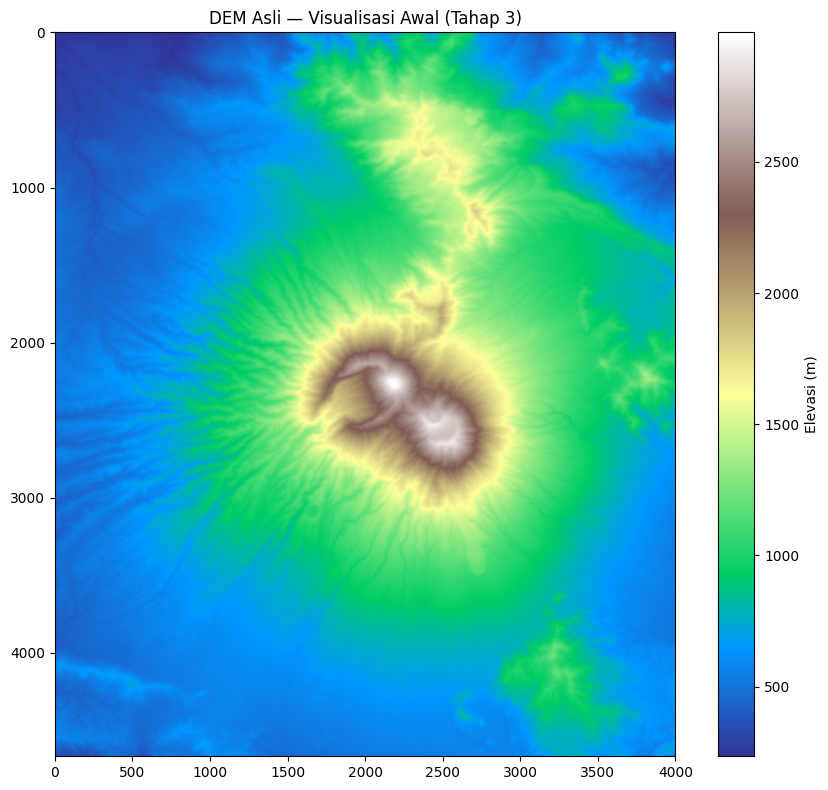

9497

In [23]:
dem_info = validate_raster(DEM_PATH, label="DEM asli (input)")

with rasterio.open(DEM_PATH) as src:
    dem_arr = src.read(1)
    dem_nodata = src.nodata
    dem_transform = src.transform
    dem_crs_src = src.crs
    dem_res = src.res
    dem_bounds = src.bounds

if dem_nodata is not None:
    dem_valid = dem_arr[dem_arr != dem_nodata]
else:
    dem_valid = dem_arr[np.isfinite(dem_arr)]

n_nodata = dem_arr.size - dem_valid.size

summary_df = pd.DataFrame({
    "Parameter": [
        "Width (px)", "Height (px)", "Band count", "Data type", "NoData value",
        "CRS (metadata asli)", "Resolusi X", "Resolusi Y",
        "Bounds left", "Bounds right", "Bounds bottom", "Bounds top",
        "Jumlah piksel NoData", "Elevasi minimum (m)", "Elevasi maksimum (m)",
        "Elevasi rata-rata (m)",
    ],
    "Nilai": [
        dem_info["width"], dem_info["height"], dem_info["count"], dem_info["dtype"],
        dem_nodata, str(dem_crs_src), dem_res[0], dem_res[1],
        dem_bounds.left, dem_bounds.right, dem_bounds.bottom, dem_bounds.top,
        n_nodata, float(dem_valid.min()), float(dem_valid.max()), float(dem_valid.mean()),
    ],
})
print()
print(summary_df.to_string(index=False))

if dem_crs_src is None:
    print("\n[PERHATIAN] Metadata CRS pada DEM ini KOSONG. Penanganan CRS "
          "dilakukan pada Tahap 4 berdasarkan koordinat bounds, bukan diasumsikan sembarangan.")

fig, ax = plt.subplots(figsize=(9, 8))
dem_plot = np.where(dem_arr == dem_nodata, np.nan, dem_arr) if dem_nodata is not None else dem_arr
im = ax.imshow(dem_plot, cmap="terrain")
ax.set_title("DEM Asli — Visualisasi Awal (Tahap 3)")
plt.colorbar(im, ax=ax, label="Elevasi (m)")
plt.tight_layout()
plt.show()
plt.close(fig)

# Bebaskan memori array resolusi penuh yang tidak dipakai lagi setelah tahap ini.
del dem_arr, dem_plot, dem_valid
gc.collect()


## TAHAP 4 — Penanganan CRS dan Reproyeksi

DEM yang diberikan memiliki metadata CRS kosong. Notebook **tidak langsung mengarang CRS** — sebagai gantinya, bounds koordinat DEM diperiksa. Jika bounds berada pada rentang:

- Longitude sekitar 106–107 BT
- Latitude sekitar -6 sampai -7 LS

maka wilayah tersebut konsisten dengan kawasan Gunung Gede–Pangrango, Jawa Barat, dan **EPSG:4326 (WGS 84 geografis)** digunakan sebagai asumsi CRS sumber — dijelaskan secara eksplisit sebagai asumsi berbasis koordinat raster, bukan fakta yang tertulis di file.

DEM kemudian direproyeksi ke **EPSG:32748 (WGS 84 / UTM Zone 48S)** agar seluruh analisis luas, panjang, dan jarak berikutnya berada dalam satuan meter yang benar.


In [24]:
SRC_CRS_ASSUMED = "EPSG:4326"
DST_CRS = "EPSG:32748"  # WGS 84 / UTM Zone 48S

lon_min, lon_max = dem_bounds.left, dem_bounds.right
lat_min, lat_max = dem_bounds.bottom, dem_bounds.top

in_gede_pangrango_range = (
    dem_crs_src is None
    and 105.0 <= lon_min <= 108.0 and 105.0 <= lon_max <= 108.0
    and -8.0 <= lat_min <= -5.0 and -8.0 <= lat_max <= -5.0
)

print(f"Bounds DEM: lon [{lon_min:.5f}, {lon_max:.5f}], lat [{lat_min:.5f}, {lat_max:.5f}]")

if dem_crs_src is not None:
    print(f"CRS metadata pada file DEM tersedia: {dem_crs_src}. CRS ini yang dipakai sebagai sumber.")
    SRC_CRS = dem_crs_src.to_string()
elif in_gede_pangrango_range:
    print(
        "CRS metadata KOSONG, namun bounds koordinat DEM konsisten dengan kawasan "
        "Gede-Pangrango (lon 106-107 BT, lat -6 s.d. -7 LS).\n"
        f"ASUMSI: CRS sumber = {SRC_CRS_ASSUMED} (WGS 84 geografis), "
        "berdasarkan rentang koordinat raster, BUKAN dari metadata file."
    )
    SRC_CRS = SRC_CRS_ASSUMED
else:
    raise ValueError(
        "CRS metadata kosong dan bounds koordinat TIDAK konsisten dengan wilayah "
        "Gede-Pangrango yang diharapkan (lon 106-107 BT, lat -6 s.d. -7 LS). "
        f"Bounds terdeteksi: lon [{lon_min:.5f}, {lon_max:.5f}], lat [{lat_min:.5f}, {lat_max:.5f}]. "
        "Tidak akan mengasumsikan CRS secara sembarangan — periksa file DEM Anda."
    )

DEM_UTM_PATH = DIR_PRE / "DEM_Gede_Pangrango_UTM48S.tif"
DST_NODATA = -9999.0

print(f"\nMereproyeksi DEM: {SRC_CRS} -> {DST_CRS}")
print(f"Output: {DEM_UTM_PATH}")

from rasterio.warp import calculate_default_transform, reproject, Resampling

with rasterio.open(DEM_PATH) as src:
    src_data = src.read(1).astype("float32")
    transform, width, height = calculate_default_transform(
        SRC_CRS, DST_CRS, src.width, src.height, *src.bounds
    )
    dst_arr = np.full((height, width), DST_NODATA, dtype="float32")
    reproject(
        source=src_data,
        destination=dst_arr,
        src_transform=src.transform,
        src_crs=SRC_CRS,
        dst_transform=transform,
        dst_crs=DST_CRS,
        resampling=Resampling.bilinear,
        src_nodata=src.nodata,
        dst_nodata=DST_NODATA,
    )
    profile = {
        "driver": "GTiff", "dtype": "float32", "nodata": DST_NODATA,
        "width": width, "height": height, "count": 1,
        "crs": DST_CRS, "transform": transform, "compress": "lzw",
    }
    with rasterio.open(DEM_UTM_PATH, "w", **profile) as dst:
        dst.write(dst_arr, 1)


dem_utm_info = validate_raster(DEM_UTM_PATH, label="DEM UTM 48S (hasil reproyeksi)")
print(f"\nCRS akhir       : {dem_utm_info['crs']}")
print(f"Resolusi (meter): {rasterio.open(DEM_UTM_PATH).res}")
print(f"Elevasi min/max : {dem_utm_info['min']:.2f} / {dem_utm_info['max']:.2f} m")

# dst_arr disimpan (dipakai lagi sebagai latar peta di Tahap 8); src_data tidak diperlukan lagi.
del src_data
gc.collect()


Bounds DEM: lon [106.79995, 107.10006], lat [-6.95005, -6.59998]
CRS metadata KOSONG, namun bounds koordinat DEM konsisten dengan kawasan Gede-Pangrango (lon 106-107 BT, lat -6 s.d. -7 LS).
ASUMSI: CRS sumber = EPSG:4326 (WGS 84 geografis), berdasarkan rentang koordinat raster, BUKAN dari metadata file.

Mereproyeksi DEM: EPSG:4326 -> EPSG:32748
Output: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\01_preprocessing\DEM_Gede_Pangrango_UTM48S.tif
  [VALID RASTER] DEM UTM 48S (hasil reproyeksi): 4019x4684, 1 band, dtype=float32, crs=EPSG:32748

CRS akhir       : EPSG:32748
Resolusi (meter): (8.29516564334673, 8.29516564334673)
Elevasi min/max : 234.32 / 2993.84 m


0

## TAHAP 5 — Hydrological Preprocessing (Depression / Sink Filling)

Mengisi cekungan (depressions/sinks) pada DEM menggunakan WhiteboxTools (`FillDepressions`), langkah wajib sebelum menghitung arah aliran, melalui `run_whitebox_checked()`.

In [25]:
DEM_FILLED_PATH = DIR_HYDRO / "dem_filled.tif"

run_whitebox_checked(
    tool_name="fill_depressions",
    params={"dem": DEM_UTM_PATH, "output": DEM_FILLED_PATH},
    expected_outputs=[DEM_FILLED_PATH],
    label="Fill Depressions (sink filling)",
)

filled_info = validate_raster(DEM_FILLED_PATH, label="DEM Filled")



>> Menjalankan proses: Fill Depressions (sink filling)
   Tool WhiteboxTools : fill_depressions
   - dem: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\01_preprocessing\DEM_Gede_Pangrango_UTM48S.tif
   - output: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\dem_filled.tif
   Status: BERHASIL (2.10 detik)
   Output tervalidasi: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\dem_filled.tif  (150,637,884 bytes)
  [VALID RASTER] DEM Filled: 4019x4684, 1 band, dtype=float64, crs=EPSG:32748


## TAHAP 6 — Flow Direction (D8)

In [26]:
FLOW_DIR_PATH = DIR_HYDRO / "flow_direction.tif"

run_whitebox_checked(
    tool_name="d8_pointer",
    params={"dem": DEM_FILLED_PATH, "output": FLOW_DIR_PATH},
    expected_outputs=[FLOW_DIR_PATH],
    label="D8 Flow Direction (Pointer)",
)

flowdir_info = validate_raster(FLOW_DIR_PATH, label="Flow Direction (D8 Pointer)")



>> Menjalankan proses: D8 Flow Direction (Pointer)
   Tool WhiteboxTools : d8_pointer
   - dem: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\dem_filled.tif
   - output: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\flow_direction.tif
   Status: BERHASIL (0.47 detik)
   Output tervalidasi: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\flow_direction.tif  (37,687,910 bytes)
  [VALID RASTER] Flow Direction (D8 Pointer): 4019x4684, 1 band, dtype=int16, crs=EPSG:32748


## TAHAP 7 — Flow Accumulation (D8)



>> Menjalankan proses: D8 Flow Accumulation
   Tool WhiteboxTools : d8_flow_accumulation
   - i: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\dem_filled.tif
   - output: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\flow_accumulation.tif
   - out_type: C:\anhid\Tugas kuliah2\python\cells
   Status: BERHASIL (1.33 detik)
   Output tervalidasi: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\flow_accumulation.tif  (75,337,902 bytes)
  [VALID RASTER] Flow Accumulation: 4019x4684, 1 band, dtype=float32, crs=EPSG:32748


C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_31312\2608264358.py:20: RuntimeWarning: invalid value encountered in log1p
  facc_log = np.where(facc_arr > 0, np.log1p(facc_arr), 0)


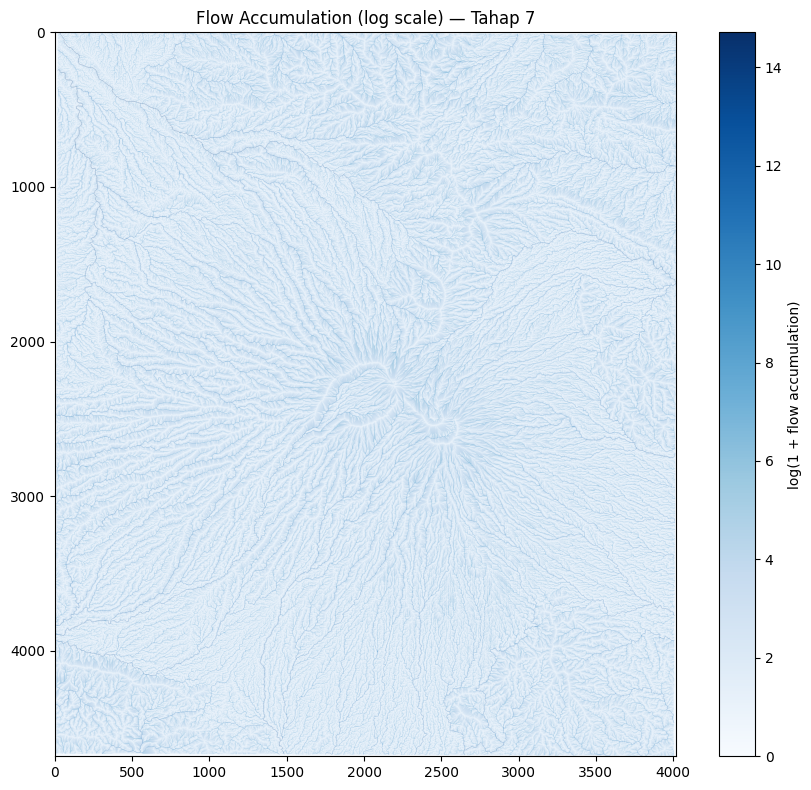

5464

In [27]:
FLOW_ACC_PATH = DIR_HYDRO / "flow_accumulation.tif"

run_whitebox_checked(
    tool_name="d8_flow_accumulation",
    params={"i": DEM_FILLED_PATH, "output": FLOW_ACC_PATH, "out_type": "cells"},
    expected_outputs=[FLOW_ACC_PATH],
    label="D8 Flow Accumulation",
)

# Baru sekarang aman untuk membuka file ini.
facc_info = validate_raster(FLOW_ACC_PATH, label="Flow Accumulation")

with rasterio.open(FLOW_ACC_PATH) as src:
    facc_arr = src.read(1)
    facc_nodata = src.nodata
    facc_transform = src.transform
    facc_crs = src.crs

facc_valid = facc_arr[facc_arr != facc_nodata] if facc_nodata is not None else facc_arr
facc_log = np.where(facc_arr > 0, np.log1p(facc_arr), 0)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(facc_log, cmap="Blues")
ax.set_title("Flow Accumulation (log scale) — Tahap 7")
plt.colorbar(im, ax=ax, label="log(1 + flow accumulation)")
plt.tight_layout()
plt.show()
plt.close(fig)

del facc_arr, facc_valid, facc_log
gc.collect()


## TAHAP 8 — Ekstraksi Jaringan Sungai

Jaringan sungai diekstrak dari flow accumulation dengan sebuah **threshold** (jumlah sel tangkapan minimum agar sebuah sel dianggap sungai).

- **Threshold kecil** → jaringan sungai lebih padat/detail (menangkap alur-alur kecil, berisiko noise).
- **Threshold besar** → jaringan sungai lebih jarang (hanya sungai-sungai besar).

Silakan ubah `STREAM_THRESHOLD` di sel berikut dan jalankan ulang dari sel ini jika hasil jaringan sungai terlalu padat/jarang dibanding kondisi lapangan yang Anda kenal.


>> Menjalankan proses: Extract Streams
   Tool WhiteboxTools : extract_streams
   - flow_accum: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\flow_accumulation.tif
   - output: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\03_streams\streams.tif
   - threshold: 500
   Status: BERHASIL (0.41 detik)
   Output tervalidasi: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\03_streams\streams.tif  (75,337,902 bytes)
  [VALID RASTER] Streams (raster): 4019x4684, 1 band, dtype=float32, crs=EPSG:32748

Jumlah sel sungai teridentifikasi: 522,193 dari 18,824,996 sel total (2.77%)


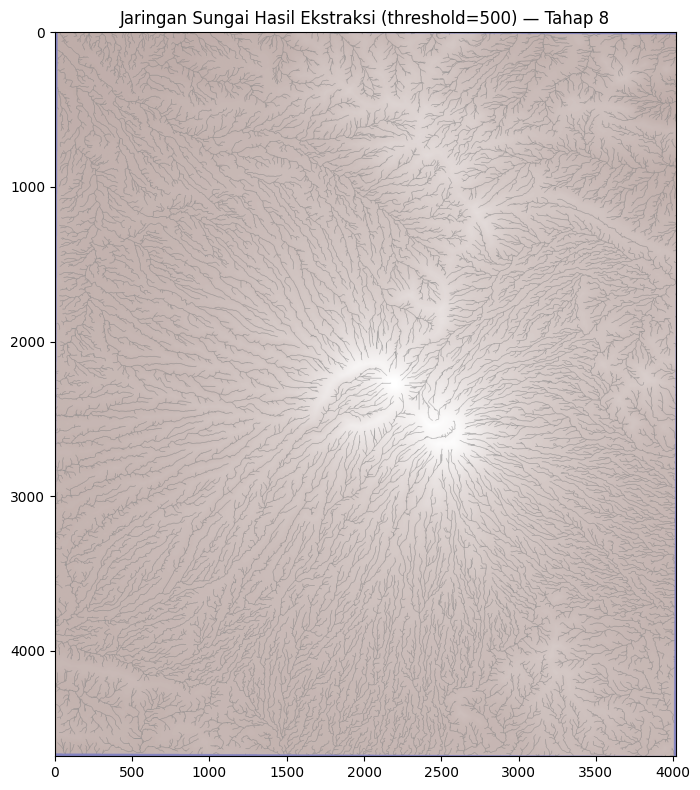

33

In [28]:

STREAM_THRESHOLD = 500

STREAMS_PATH = DIR_STREAMS / "streams.tif"

run_whitebox_checked(
    tool_name="extract_streams",
    params={"flow_accum": FLOW_ACC_PATH, "output": STREAMS_PATH, "threshold": STREAM_THRESHOLD},
    expected_outputs=[STREAMS_PATH],
    label="Extract Streams",
)

streams_info = validate_raster(STREAMS_PATH, label="Streams (raster)", check_not_all_nodata=False)

with rasterio.open(STREAMS_PATH) as src:
    streams_arr = src.read(1)
    streams_nodata = src.nodata

n_stream_cells = int(np.sum(streams_arr == 1))
print(f"\nJumlah sel sungai teridentifikasi: {n_stream_cells:,} dari {streams_arr.size:,} sel total "
      f"({100*n_stream_cells/streams_arr.size:.2f}%)")
if n_stream_cells == 0:
    raise ValueError(
        f"STREAM_THRESHOLD={STREAM_THRESHOLD} terlalu besar -- tidak ada sel yang lolos sebagai "
        "sungai. Turunkan nilai STREAM_THRESHOLD lalu jalankan ulang dari sel ini."
    )

fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(np.where(streams_arr == 1, np.nan, dst_arr), cmap="terrain", alpha=0.6)
stream_mask = np.where(streams_arr == 1, 1, np.nan)
ax.imshow(stream_mask, cmap="Blues_r", vmin=0, vmax=1)
ax.set_title(f"Jaringan Sungai Hasil Ekstraksi (threshold={STREAM_THRESHOLD}) — Tahap 8")
plt.tight_layout()
plt.show()
plt.close(fig)

del dst_arr, stream_mask
gc.collect()


## TAHAP 9 — Pemilihan Outlet

DEM yang tersedia **tidak dilengkapi titik outlet**. Notebook ini menampilkan hillshade + DEM + jaringan sungai, lalu menawarkan tiga cara memilih outlet, dicoba berurutan:

1. **Klik interaktif** dengan `matplotlib.ginput()` — bila backend matplotlib mendukung interaksi (mis. `%matplotlib qt` atau `%matplotlib tk` di Jupyter/VS Code klasik).
2. **Input manual koordinat** — Anda mengisi `MANUAL_OUTLET_X` / `MANUAL_OUTLET_Y` (koordinat UTM 48S, meter) pada sel konfigurasi di bawah lalu set `OUTLET_MODE = "manual"`.
3. **Fallback otomatis** (`OUTLET_MODE = "auto"`) — memilih sel dengan flow accumulation tertinggi di sepanjang tepi DEM sebagai perkiraan titik keluar sungai utama. **Mode ini hanya untuk menjaga notebook tetap bisa dijalankan ulang (Restart & Run All) secara headless** (misalnya saat diverifikasi otomatis) — untuk analisis Sub-DAS yang sesungguhnya, Anda **sangat dianjurkan** memakai mode `"interactive"` atau `"manual"` agar outlet sesuai lokasi yang benar-benar Anda maksud.

Koordinat outlet **tidak pernah dikarang** oleh notebook — pada mode `interactive`/`manual` koordinat berasal murni dari input Anda, dan pada mode `auto` koordinat berasal dari nilai flow accumulation maksimum aktual pada DEM (bukan angka tetap).

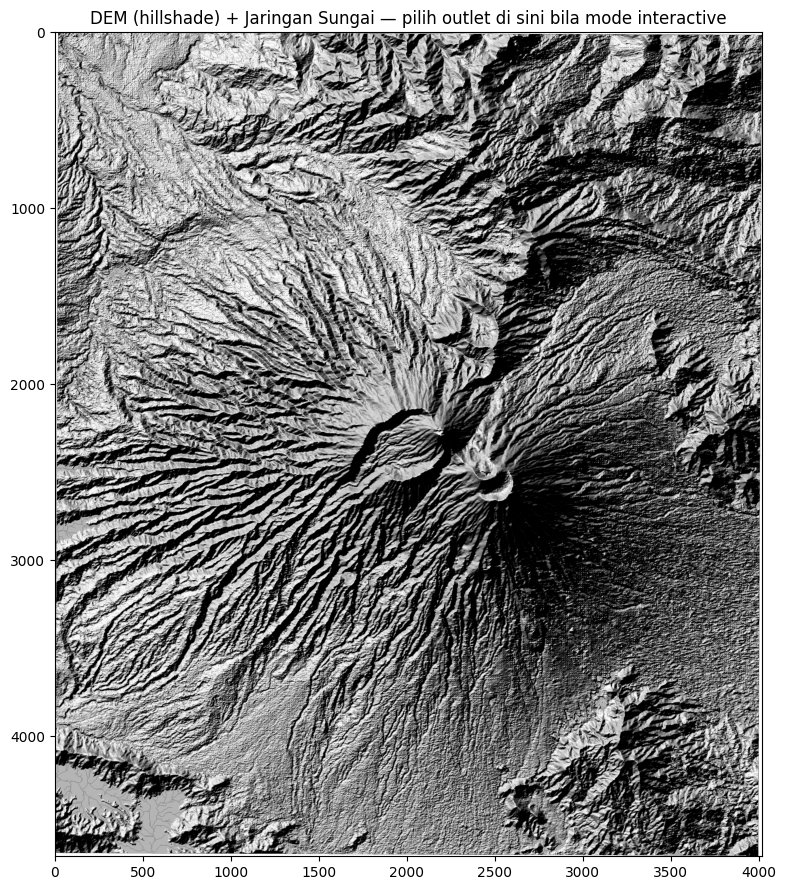


Mode AUTO: DEM ini tidak dilengkapi outlet, sehingga dipilih sebuah titik pada
jaringan sungai yang menghasilkan luas tangkapan (drainage area) pada rentang
representatif Sub-DAS (500-1500 ha), BUKAN outlet
keseluruhan DEM. Ini murni fallback otomatis untuk menjaga notebook tetap bisa
dijalankan ulang tanpa interaksi -- untuk analisis sesungguhnya gunakan mode
'interactive' atau 'manual' agar lokasi outlet sesuai maksud Anda.

Sel terpilih otomatis: row=1572, col=3217
Perkiraan luas tangkapan pada titik ini: 1,000.0 ha (target: 500-1500 ha)
Koordinat outlet (auto): (725549.61, 9257067.52) UTM 48S

[OK] Outlet awal (sebelum snapping): X=725549.61, Y=9257067.52 (EPSG:32748)
  [VALID VECTOR] Outlet (sebelum snap): 1 feature(s), crs=EPSG:32748, geom_type=['Point']

>> Menjalankan proses: Snap Outlet ke Jaringan Sungai (Jenson Snap Pour Points)
   Tool WhiteboxTools : jenson_snap_pour_points
   - pour_pts: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\04_watershed\outlet_raw.shp
   - st

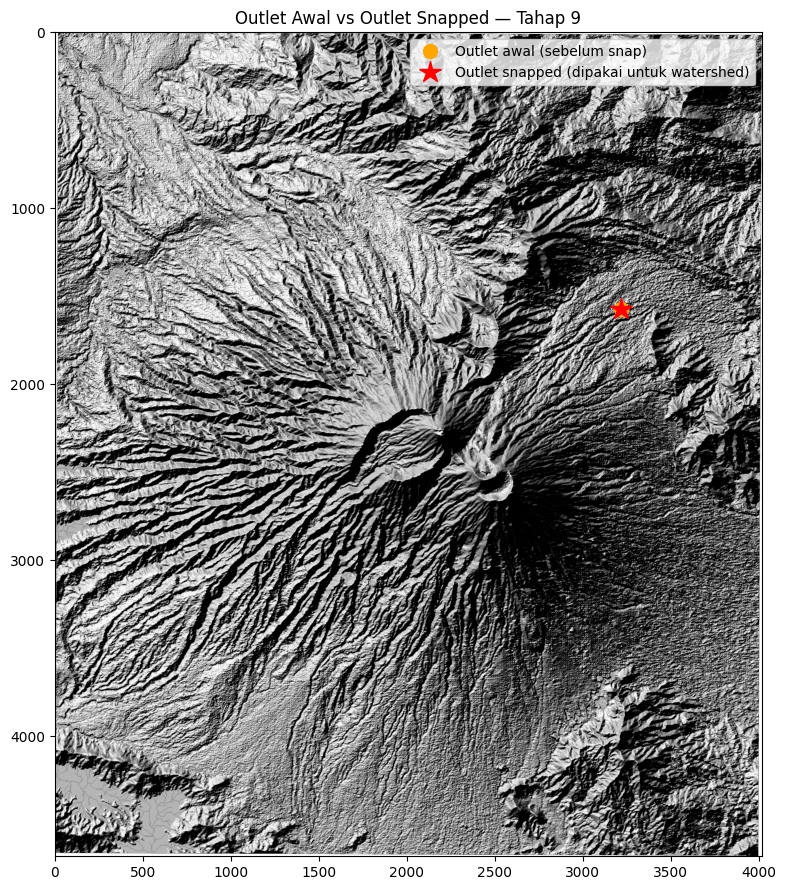

6738

In [29]:
# KONFIGURASI OUTLET
# Pilih salah satu: "interactive", "manual", "auto"
OUTLET_MODE = "auto"

# Dipakai hanya jika OUTLET_MODE == "manual" (koordinat UTM 48S, satuan meter)
MANUAL_OUTLET_X = None
MANUAL_OUTLET_Y = None

AUTO_TARGET_AREA_HA_MIN = 500.0
AUTO_TARGET_AREA_HA_MAX = 1500.0

with rasterio.open(DEM_FILLED_PATH) as src:
    filled_arr = src.read(1)
    filled_transform = src.transform
    filled_crs = src.crs
    filled_nodata = src.nodata

from matplotlib.colors import LightSource
ls = LightSource(azdeg=315, altdeg=45)
hillshade_preview = ls.hillshade(np.where(filled_arr == filled_nodata, np.nan, filled_arr), vert_exag=1)

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(hillshade_preview, cmap="gray")
ax.imshow(np.where(streams_arr == 1, 1, np.nan), cmap="Blues_r", vmin=0, vmax=1, alpha=0.9)
ax.set_title("DEM (hillshade) + Jaringan Sungai — pilih outlet di sini bila mode interactive")
plt.tight_layout()

outlet_x = outlet_y = None

if OUTLET_MODE == "interactive":
    print("\nSilakan KLIK satu titik pada peta di atas untuk menentukan lokasi outlet Sub-DAS.")
    try:
        backend = matplotlib.get_backend()
        print(f"Backend matplotlib saat ini: {backend}")
        pts = plt.ginput(1, timeout=60)
        plt.close(fig)
        if not pts:
            raise RuntimeError("Tidak ada titik yang diklik dalam batas waktu (timeout).")
        col_click, row_click = pts[0]
        outlet_x, outlet_y = rasterio.transform.xy(filled_transform, int(round(row_click)), int(round(col_click)))
        print(f"Titik diklik pada (row={row_click:.1f}, col={col_click:.1f}) -> koordinat UTM ({outlet_x:.2f}, {outlet_y:.2f})")
    except Exception as e:
        print(f"\n[PERINGATAN] ginput() tidak dapat dipakai pada environment ini: {e}")
        print("Backend matplotlib Anda kemungkinan tidak mendukung interaksi (mis. 'inline' atau 'agg').")
        print("Solusi: jalankan '%matplotlib qt' atau '%matplotlib tk' di sel sebelum ini, lalu jalankan ulang sel ini,")
        print("ATAU ubah OUTLET_MODE menjadi 'manual' dan isi MANUAL_OUTLET_X / MANUAL_OUTLET_Y,")
        print("ATAU ubah OUTLET_MODE menjadi 'auto' untuk fallback otomatis.")
        raise

elif OUTLET_MODE == "manual":
    plt.show()
    if MANUAL_OUTLET_X is None or MANUAL_OUTLET_Y is None:
        raise ValueError(
            "OUTLET_MODE='manual' tetapi MANUAL_OUTLET_X / MANUAL_OUTLET_Y belum diisi. "
            "Lihat peta di atas untuk memperkirakan koordinat UTM 48S outlet yang Anda inginkan, "
            "lalu isi kedua variabel tersebut pada sel konfigurasi dan jalankan ulang."
        )
    outlet_x, outlet_y = float(MANUAL_OUTLET_X), float(MANUAL_OUTLET_Y)
    print(f"Outlet manual: ({outlet_x:.2f}, {outlet_y:.2f}) UTM 48S")

elif OUTLET_MODE == "auto":
    plt.show()
    print("\nMode AUTO: DEM ini tidak dilengkapi outlet, sehingga dipilih sebuah titik pada")
    print("jaringan sungai yang menghasilkan luas tangkapan (drainage area) pada rentang")
    print(f"representatif Sub-DAS ({AUTO_TARGET_AREA_HA_MIN:.0f}-{AUTO_TARGET_AREA_HA_MAX:.0f} ha), BUKAN outlet")
    print("keseluruhan DEM. Ini murni fallback otomatis untuk menjaga notebook tetap bisa")
    print("dijalankan ulang tanpa interaksi -- untuk analisis sesungguhnya gunakan mode")
    print("'interactive' atau 'manual' agar lokasi outlet sesuai maksud Anda.")

    with rasterio.open(FLOW_ACC_PATH) as src:
        facc_full = src.read(1)
        facc_nd = src.nodata
        cell_area_m2 = abs(src.res[0] * src.res[1])

    stream_mask_full = (streams_arr == 1)
    valid_mask = (facc_full != facc_nd) if facc_nd is not None else np.isfinite(facc_full)
    # Buang pinggiran DEM (drainase area di tepi tidak dapat dipercaya / terpotong).
    edge_buffer = 15
    interior_mask = np.zeros_like(valid_mask)
    interior_mask[edge_buffer:-edge_buffer, edge_buffer:-edge_buffer] = True

    candidate_mask = stream_mask_full & valid_mask & interior_mask
    drainage_area_ha = (facc_full * cell_area_m2) / 10_000.0
    target_ha = (AUTO_TARGET_AREA_HA_MIN + AUTO_TARGET_AREA_HA_MAX) / 2.0

    diff = np.where(candidate_mask, np.abs(drainage_area_ha - target_ha), np.inf)
    if not np.isfinite(diff).any():
        raise RuntimeError(
            "Mode AUTO gagal menemukan titik sungai kandidat pada interior DEM. "
            "Gunakan OUTLET_MODE='manual' atau 'interactive'."
        )
    row, col = np.unravel_index(np.argmin(diff), diff.shape)
    outlet_x, outlet_y = rasterio.transform.xy(filled_transform, row, col)
    chosen_area_ha = float(drainage_area_ha[row, col])
    print(f"\nSel terpilih otomatis: row={row}, col={col}")
    print(f"Perkiraan luas tangkapan pada titik ini: {chosen_area_ha:,.1f} ha "
          f"(target: {AUTO_TARGET_AREA_HA_MIN:.0f}-{AUTO_TARGET_AREA_HA_MAX:.0f} ha)")
    print(f"Koordinat outlet (auto): ({outlet_x:.2f}, {outlet_y:.2f}) UTM 48S")
    del facc_full, drainage_area_ha, diff, candidate_mask, valid_mask, interior_mask, stream_mask_full

else:
    raise ValueError(f"OUTLET_MODE tidak dikenali: {OUTLET_MODE!r}. Gunakan 'interactive', 'manual', atau 'auto'.")

if outlet_x is None or outlet_y is None:
    raise RuntimeError("Outlet belum berhasil ditentukan. Periksa OUTLET_MODE dan ulangi Tahap 9.")

print(f"\n[OK] Outlet awal (sebelum snapping): X={outlet_x:.2f}, Y={outlet_y:.2f} (EPSG:32748)")

# --- Buat point, snap ke jaringan sungai ---
from shapely.geometry import Point

OUTLET_RAW_SHP = DIR_WATERSHED / "outlet_raw.shp"
OUTLET_SNAPPED_SHP = DIR_WATERSHED / "outlet_snapped.shp"

outlet_raw_gdf = gpd.GeoDataFrame({"id": [1]}, geometry=[Point(outlet_x, outlet_y)], crs=DST_CRS)
# WhiteboxTools hanya membaca vector dalam format Shapefile, bukan GeoPackage.
outlet_raw_gdf.to_file(OUTLET_RAW_SHP, driver="ESRI Shapefile")
validate_vector(OUTLET_RAW_SHP, label="Outlet (sebelum snap)")

SNAP_DISTANCE_M = 100.0
run_whitebox_checked(
    tool_name="jenson_snap_pour_points",
    params={"pour_pts": OUTLET_RAW_SHP, "streams": STREAMS_PATH, "output": OUTLET_SNAPPED_SHP,
            "snap_dist": SNAP_DISTANCE_M},
    expected_outputs=[OUTLET_SNAPPED_SHP],
    label="Snap Outlet ke Jaringan Sungai (Jenson Snap Pour Points)",
)

outlet_snapped_gdf = validate_vector(OUTLET_SNAPPED_SHP, label="Outlet (setelah snap)")
outlet_snapped_pt = outlet_snapped_gdf.geometry.iloc[0]
print(f"\nOutlet awal   : ({outlet_x:.2f}, {outlet_y:.2f})")
print(f"Outlet snapped: ({outlet_snapped_pt.x:.2f}, {outlet_snapped_pt.y:.2f})")
shift_m = ((outlet_snapped_pt.x - outlet_x)**2 + (outlet_snapped_pt.y - outlet_y)**2) ** 0.5
print(f"Pergeseran akibat snapping: {shift_m:.2f} m")

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(hillshade_preview, cmap="gray")
ax.imshow(np.where(streams_arr == 1, 1, np.nan), cmap="Blues_r", vmin=0, vmax=1, alpha=0.9)
row_o, col_o = rasterio.transform.rowcol(filled_transform, outlet_x, outlet_y)
row_s, col_s = rasterio.transform.rowcol(filled_transform, outlet_snapped_pt.x, outlet_snapped_pt.y)
ax.plot(col_o, row_o, "o", color="orange", markersize=10, label="Outlet awal (sebelum snap)")
ax.plot(col_s, row_s, "*", color="red", markersize=16, label="Outlet snapped (dipakai untuk watershed)")
ax.legend(loc="upper right")
ax.set_title("Outlet Awal vs Outlet Snapped — Tahap 9")
plt.tight_layout()
plt.show()
plt.close(fig)

del filled_arr, hillshade_preview
gc.collect()


## TAHAP 10 — Delineasi Sub-DAS (Watershed)

Menggunakan flow direction dan outlet yang telah di-snap untuk mendelineasi batas Sub-DAS, lalu mengonversinya menjadi polygon dan menghitung statistik luas/elevasi dari DEM+watershed hasil analisis (bukan angka tetap).

In [30]:
WATERSHED_RASTER_PATH = DIR_WATERSHED / "watershed.tif"
WATERSHED_POLY_SHP = DIR_WATERSHED / "watershed_poly.shp"  # intermediate (whitebox butuh .shp)
SUBDAS_GPKG_PATH = DIR_VECTOR / "SubDAS_Gede_Pangrango.gpkg"

run_whitebox_checked(
    tool_name="watershed",
    params={"d8_pntr": FLOW_DIR_PATH, "pour_pts": OUTLET_SNAPPED_SHP, "output": WATERSHED_RASTER_PATH},
    expected_outputs=[WATERSHED_RASTER_PATH],
    label="Watershed Delineation",
)
watershed_raster_info = validate_raster(WATERSHED_RASTER_PATH, label="Watershed (raster)",
                                          check_not_all_nodata=False)

with rasterio.open(WATERSHED_RASTER_PATH) as src:
    ws_arr = src.read(1)
    ws_nodata = src.nodata
n_ws_cells = int(np.sum((ws_arr > 0) & (ws_arr != ws_nodata if ws_nodata is not None else True)))
if n_ws_cells == 0:
    raise ValueError(
        "Watershed hasil delineasi KOSONG (0 sel). Outlet yang dipilih kemungkinan tidak "
        "berada pada / dekat jaringan sungai yang valid. Ulangi Tahap 9 dengan outlet lain."
    )
print(f"Jumlah sel dalam Sub-DAS: {n_ws_cells:,}")

run_whitebox_checked(
    tool_name="raster_to_vector_polygons",
    params={"i": WATERSHED_RASTER_PATH, "output": WATERSHED_POLY_SHP},
    expected_outputs=[WATERSHED_POLY_SHP],
    label="Watershed Raster to Polygon",
)
watershed_poly_gdf = validate_vector(WATERSHED_POLY_SHP, label="Watershed Polygon (raw)")

# Watershed raster bisa terpolygon jadi >1 feature (mis. pixel-pixel kecil terpisah akibat
# noise D8). Ambil polygon dengan luas terbesar sebagai Sub-DAS utama, dan gabungkan semua
# polygon bervalue watershed (>0) agar tidak kehilangan bagian tepi yang valid.
value_col = "VALUE" if "VALUE" in watershed_poly_gdf.columns else watershed_poly_gdf.columns[0]
watershed_poly_gdf = watershed_poly_gdf[watershed_poly_gdf[value_col] > 0].copy()
if len(watershed_poly_gdf) == 0:
    raise ValueError("Tidak ada polygon watershed dengan VALUE > 0 setelah vektorisasi.")

merged_geom = watershed_poly_gdf.geometry.union_all() if hasattr(watershed_poly_gdf.geometry, "union_all") \
    else watershed_poly_gdf.geometry.unary_union
subdas_gdf = gpd.GeoDataFrame({"id": [1], "nama": ["Sub-DAS Gede-Pangrango"]},
                                geometry=[merged_geom], crs=DST_CRS)

# --- Statistik luas/perimeter (dihitung dari geometri di CRS metrik UTM) ---
area_m2 = float(subdas_gdf.geometry.area.iloc[0])
perim_m = float(subdas_gdf.geometry.length.iloc[0])
area_ha = area_m2 / 10_000.0
area_km2 = area_m2 / 1_000_000.0
perim_km = perim_m / 1000.0

# --- Statistik elevasi dalam Sub-DAS (dari DEM filled, bukan nilai fiktif) ---
from rasterio.mask import mask as rio_mask
with rasterio.open(DEM_FILLED_PATH) as src:
    clip_img, clip_transform = rio_mask(src, subdas_gdf.geometry, crop=True, nodata=DST_NODATA)
    clip_elev = clip_img[0]
clip_valid = clip_elev[clip_elev != DST_NODATA]
elev_min = float(clip_valid.min())
elev_max = float(clip_valid.max())
elev_mean = float(clip_valid.mean())

subdas_gdf["luas_m2"] = area_m2
subdas_gdf["luas_ha"] = area_ha
subdas_gdf["luas_km2"] = area_km2
subdas_gdf["perimeter_km"] = perim_km
subdas_gdf["elev_min_m"] = elev_min
subdas_gdf["elev_max_m"] = elev_max
subdas_gdf["elev_mean_m"] = elev_mean

subdas_gdf.to_file(SUBDAS_GPKG_PATH, driver="GPKG")
validate_vector(SUBDAS_GPKG_PATH, label="Sub-DAS (GPKG final)")

print("\n=== STATISTIK SUB-DAS (dihitung dari DEM & outlet aktual) ===")
print(f"Luas       : {area_m2:,.1f} m2  =  {area_ha:,.2f} ha  =  {area_km2:,.3f} km2")
print(f"Perimeter  : {perim_km:,.2f} km")
print(f"Elevasi    : min={elev_min:.1f} m, max={elev_max:.1f} m, mean={elev_mean:.1f} m")

del ws_arr, clip_img, clip_elev, clip_valid
gc.collect()



>> Menjalankan proses: Watershed Delineation
   Tool WhiteboxTools : watershed
   - d8_pntr: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\flow_direction.tif
   - pour_pts: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\04_watershed\outlet_snapped.shp
   - output: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\04_watershed\watershed.tif
   Status: BERHASIL (0.94 detik)
   Output tervalidasi: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\04_watershed\watershed.tif  (75,337,902 bytes)
  [VALID RASTER] Watershed (raster): 4019x4684, 1 band, dtype=int32, crs=EPSG:32748
Jumlah sel dalam Sub-DAS: 145,328

>> Menjalankan proses: Watershed Raster to Polygon
   Tool WhiteboxTools : raster_to_vector_polygons
   - i: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\04_watershed\watershed.tif
   - output: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\04_watershed\watershed_poly.shp
   Status: BERHASIL (0.30 detik)
   Output tervalidasi: C:\anhid\Tugas kuliah2\python\HASI

0

## TAHAP 11 — Clip DEM dan Hillshade

Memotong DEM sesuai batas Sub-DAS, lalu membuat hillshade dari DEM penuh (whitebox `Hillshade`) untuk dipakai sebagai latar peta akhir.

In [31]:
DEM_SUBDAS_PATH = DIR_WATERSHED / "dem_subdas.tif"
with rasterio.open(DEM_FILLED_PATH) as src:
    clip_img2, clip_transform2 = rio_mask(src, subdas_gdf.geometry, crop=True, nodata=DST_NODATA)
    clip_meta = src.meta.copy()
    clip_meta.update({
        "height": clip_img2.shape[1], "width": clip_img2.shape[2],
        "transform": clip_transform2, "nodata": DST_NODATA,
    })
    with rasterio.open(DEM_SUBDAS_PATH, "w", **clip_meta) as dst:
        dst.write(clip_img2)

validate_raster(DEM_SUBDAS_PATH, label="DEM Sub-DAS (clipped)")

HILLSHADE_PATH = DIR_WATERSHED / "hillshade.tif"
run_whitebox_checked(
    tool_name="hillshade",
    params={"dem": DEM_FILLED_PATH, "output": HILLSHADE_PATH, "azimuth": 315.0, "altitude": 45.0},
    expected_outputs=[HILLSHADE_PATH],
    label="Hillshade (multi-directional relief)",
)
validate_raster(HILLSHADE_PATH, label="Hillshade")
print("\nCatatan: hillshade dibuat dari DEM penuh (bukan DEM ter-clip) agar transisi visual di")
print("tepi Sub-DAS pada peta akhir tetap halus; hillshade akan di-clip saat plotting bila perlu.")

del clip_img2
gc.collect()


  [VALID RASTER] DEM Sub-DAS (clipped): 816x975, 1 band, dtype=float64, crs=EPSG:32748

>> Menjalankan proses: Hillshade (multi-directional relief)
   Tool WhiteboxTools : hillshade
   - dem: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\dem_filled.tif
   - output: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\04_watershed\hillshade.tif
   - azimuth: 315.0
   - altitude: 45.0
   Status: BERHASIL (0.89 detik)
   Output tervalidasi: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\04_watershed\hillshade.tif  (37,687,910 bytes)
  [VALID RASTER] Hillshade: 4019x4684, 1 band, dtype=int16, crs=EPSG:32748

Catatan: hillshade dibuat dari DEM penuh (bukan DEM ter-clip) agar transisi visual di
tepi Sub-DAS pada peta akhir tetap halus; hillshade akan di-clip saat plotting bila perlu.


0

## TAHAP 12 — Orde Sungai Strahler

Menghitung orde Strahler yang benar (WhiteboxTools `StrahlerStreamOrder`, yang mengimplementasikan aturan klasik):

- Sungai awal (ujung/headwater) = orde 1.
- Dua sungai orde N yang bertemu menghasilkan orde N+1.
- Sungai orde berbeda yang bertemu mengikuti orde yang **lebih besar** (tidak naik orde).

Orde disimpan sebagai raster (`stream_order.tif`) dan sebagai atribut pada vector (`streams_strahler.gpkg`).

In [32]:
STREAM_ORDER_PATH = DIR_STREAMS / "stream_order.tif"

run_whitebox_checked(
    tool_name="strahler_stream_order",
    params={"d8_pntr": FLOW_DIR_PATH, "streams": STREAMS_PATH, "output": STREAM_ORDER_PATH},
    expected_outputs=[STREAM_ORDER_PATH],
    label="Strahler Stream Order",
)
validate_raster(STREAM_ORDER_PATH, label="Stream Order (raster)", check_not_all_nodata=False)

with rasterio.open(STREAM_ORDER_PATH) as src:
    sorder_arr = src.read(1)
    sorder_nodata = src.nodata

order_valid = sorder_arr[(sorder_arr != sorder_nodata) & (sorder_arr > 0)] if sorder_nodata is not None \
    else sorder_arr[sorder_arr > 0]
orders_found = sorted(int(o) for o in np.unique(order_valid))
print(f"\nOrde yang ditemukan pada DEM ini: {orders_found}")
if not orders_found:
    raise ValueError("Tidak ada orde sungai yang terdeteksi -- periksa STREAM_THRESHOLD pada Tahap 8.")
ORDE_MAKS = max(orders_found)
print(f"Orde maksimum: {ORDE_MAKS}")
print("(Notebook TIDAK memaksakan orde 4 atau lebih apabila data hanya menghasilkan orde yang lebih rendah.)")

STREAMS_VEC_SHP = DIR_STREAMS / "streams_order_vec.shp"
STREAMS_STRAHLER_GPKG = DIR_VECTOR / "Jaringan_Sungai_Strahler.gpkg"

run_whitebox_checked(
    tool_name="raster_streams_to_vector",
    params={"streams": STREAM_ORDER_PATH, "d8_pntr": FLOW_DIR_PATH, "output": STREAMS_VEC_SHP},
    expected_outputs=[STREAMS_VEC_SHP],
    label="Raster Streams to Vector (dengan atribut orde)",
)
streams_vec_gdf = validate_vector(STREAMS_VEC_SHP, label="Jaringan Sungai (vector, raw)")

order_col = "STRM_VAL" if "STRM_VAL" in streams_vec_gdf.columns else streams_vec_gdf.columns[0]
streams_vec_gdf["orde"] = streams_vec_gdf[order_col].round().astype(int)
streams_vec_gdf = streams_vec_gdf[streams_vec_gdf["orde"] > 0].copy()

orders_in_vector = sorted(streams_vec_gdf["orde"].unique().tolist())
print(f"\nOrde yang ditemukan pada VECTOR jaringan sungai: {orders_in_vector}")
if set(orders_in_vector) != set(orders_found):
    print(f"[PERHATIAN] Orde pada raster ({orders_found}) dan vector ({orders_in_vector}) "
          "sedikit berbeda -- ini dapat terjadi akibat pembulatan / sel tepi saat vektorisasi, "
          "dan tidak memengaruhi validitas topologi jaringan.")

# Hanya simpan jaringan sungai yang berada dalam batas Sub-DAS untuk peta akhir.
streams_in_subdas = gpd.overlay(streams_vec_gdf[["orde", "geometry"]], subdas_gdf[["id", "geometry"]],
                                  how="intersection")
if len(streams_in_subdas) == 0:
    raise ValueError(
        "Tidak ada ruas sungai yang berpotongan dengan polygon Sub-DAS. Kemungkinan outlet "
        "(Tahap 9) tidak terhubung dengan jaringan sungai yang benar."
    )
streams_in_subdas.to_file(STREAMS_STRAHLER_GPKG, driver="GPKG")
validate_vector(STREAMS_STRAHLER_GPKG, label="Jaringan Sungai Strahler (GPKG final, dalam Sub-DAS)")

orders_final = sorted(streams_in_subdas["orde"].unique().tolist())
print(f"\nOrde sungai final DALAM Sub-DAS: {orders_final}")
ORDE_MAKS_SUBDAS = max(orders_final)
print(f"Orde maksimum dalam Sub-DAS: {ORDE_MAKS_SUBDAS}")

del sorder_arr, order_valid, streams_vec_gdf
gc.collect()



>> Menjalankan proses: Strahler Stream Order
   Tool WhiteboxTools : strahler_stream_order
   - d8_pntr: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\flow_direction.tif
   - streams: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\03_streams\streams.tif
   - output: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\03_streams\stream_order.tif
   Status: BERHASIL (0.77 detik)
   Output tervalidasi: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\03_streams\stream_order.tif  (75,337,902 bytes)
  [VALID RASTER] Stream Order (raster): 4019x4684, 1 band, dtype=float32, crs=EPSG:32748

Orde yang ditemukan pada DEM ini: [1, 2, 3, 4, 5, 6]
Orde maksimum: 6
(Notebook TIDAK memaksakan orde 4 atau lebih apabila data hanya menghasilkan orde yang lebih rendah.)

>> Menjalankan proses: Raster Streams to Vector (dengan atribut orde)
   Tool WhiteboxTools : raster_streams_to_vector
   - streams: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\03_streams\stream_order.tif
   - d8_pnt

C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_31312\144114296.py:48: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: None
Right CRS: EPSG:32748

  streams_in_subdas = gpd.overlay(streams_vec_gdf[["orde", "geometry"]], subdas_gdf[["id", "geometry"]],
C:\Users\Yusufalqodri\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pyogrio\geopandas.py:710: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(


  [VALID VECTOR] Jaringan Sungai Strahler (GPKG final, dalam Sub-DAS): 112 feature(s), crs=None, geom_type=['LineString']

Orde sungai final DALAM Sub-DAS: [1, 2, 3, 4]
Orde maksimum dalam Sub-DAS: 4


0

## TAHAP 13 — Identifikasi Sungai Utama

Sungai utama diidentifikasi dari **struktur topologi jaringan** (bukan satu segmen acak), dengan kombinasi:

1. Orde tertinggi yang ditemukan di Sub-DAS (`ORDE_MAKS_SUBDAS`).
2. Kontinuitas downstream — ruas-ruas orde tertinggi digabung (dissolve) menjadi satu jalur utuh.
3. Di antara jalur-jalur yang terbentuk pada orde tertinggi, dipilih yang **paling panjang** sebagai sungai utama (mewakili batang sungai yang benar-benar menerus, bukan potongan pendek).

In [33]:
main_order_segments = streams_in_subdas[streams_in_subdas["orde"] == ORDE_MAKS_SUBDAS].copy()
print(f"Jumlah ruas pada orde tertinggi ({ORDE_MAKS_SUBDAS}): {len(main_order_segments)}")

# Gabungkan ruas-ruas yang terhubung menjadi jalur menerus (multi-part geometry),
# lalu pisahkan kembali jadi single LineString untuk memilih jalur terpanjang.
from shapely.ops import linemerge
merged = linemerge(main_order_segments.geometry.union_all()
                    if hasattr(main_order_segments.geometry, "union_all")
                    else main_order_segments.geometry.unary_union)

if merged.geom_type == "LineString":
    candidate_lines = [merged]
elif merged.geom_type == "MultiLineString":
    candidate_lines = list(merged.geoms)
else:
    candidate_lines = [g for g in merged.geoms] if hasattr(merged, "geoms") else [merged]

lengths = [g.length for g in candidate_lines]
main_idx = int(np.argmax(lengths))
main_stream_geom = candidate_lines[main_idx]
main_stream_length_km = main_stream_geom.length / 1000.0

print(f"Sungai utama terpilih: jalur terpanjang di antara {len(candidate_lines)} jalur pada orde {ORDE_MAKS_SUBDAS}")
print(f"Panjang sungai utama: {main_stream_length_km:.2f} km")

main_stream_gdf = gpd.GeoDataFrame(
    {"nama": [f"Sungai Utama - Ordo {ORDE_MAKS_SUBDAS}"], "orde": [ORDE_MAKS_SUBDAS],
     "panjang_km": [main_stream_length_km]},
    geometry=[main_stream_geom], crs=DST_CRS,
)
MAIN_STREAM_LABEL = f"Sungai Utama \u2014 Ordo {ORDE_MAKS_SUBDAS}"
print(f"Label peta: '{MAIN_STREAM_LABEL}'")


Jumlah ruas pada orde tertinggi (4): 7
Sungai utama terpilih: jalur terpanjang di antara 1 jalur pada orde 4
Panjang sungai utama: 3.62 km
Label peta: 'Sungai Utama — Ordo 4'


## TAHAP 14 — Titik Confluence (Pertemuan Sungai)

Titik confluence dihitung dari **topologi jaringan** (graph dari titik ujung tiap ruas sungai), bukan ditandai secara manual. Sebuah node dianggap confluence yang valid untuk dilabeli apabila:

- Derajat node >= 3 (pertemuan nyata, bukan sekadar titik tengah satu garis), **dan**
- Terdapat minimal dua ruas dengan orde yang sama (X) bertemu di titik tersebut, membentuk kelanjutan berorde X atau lebih tinggi (X+1) sesuai aturan Strahler.

Untuk menjaga peta tetap terbaca, hanya confluence pada orde tertinggi yang tersedia (mendekati sungai utama) yang diberi label — sesuai instruksi untuk **tidak memenuhi peta dengan label**.

In [34]:
import networkx as nx
from shapely.geometry import Point as ShpPoint

def _endpoint_key(pt, precision=1):
    return (round(pt.x, precision), round(pt.y, precision))

G = nx.MultiGraph()
for _, row in streams_in_subdas.iterrows():
    geom = row.geometry
    lines = list(geom.geoms) if geom.geom_type == "MultiLineString" else [geom]
    for line in lines:
        coords = list(line.coords)
        if len(coords) < 2:
            continue
        p0 = _endpoint_key(ShpPoint(coords[0]))
        p1 = _endpoint_key(ShpPoint(coords[-1]))
        G.add_edge(p0, p1, orde=int(row["orde"]))

confluence_candidates = []
for node in G.nodes():
    deg = G.degree(node)
    if deg < 3:
        continue
    incident_orders = [d["orde"] for _, _, d in G.edges(node, data=True)]
    max_o = max(incident_orders)
    count_max_o = incident_orders.count(max_o)
    # Confluence Strahler valid: >=2 ruas dengan orde sama = max_o bertemu di node ini.
    if count_max_o >= 2:
        confluence_candidates.append({"node": node, "orde": max_o, "degree": deg})

print(f"Jumlah node persimpangan (derajat>=3): "
      f"{sum(1 for n in G.nodes() if G.degree(n) >= 3)}")
print(f"Jumlah confluence Strahler valid (>=2 ruas seorde bertemu): {len(confluence_candidates)}")

if confluence_candidates:
    conf_orders_present = sorted({c['orde'] for c in confluence_candidates})
    print(f"Orde confluence yang tersedia: {conf_orders_present}")
    # Hanya tampilkan confluence pada 1-2 orde tertinggi agar peta tidak penuh label.
    label_min_order = max(conf_orders_present[-1] - 1, min(conf_orders_present))
    important = [c for c in confluence_candidates if c["orde"] >= label_min_order]
    important = sorted(important, key=lambda c: -c["orde"])

    # Filter spasial (greedy): banyak confluence Strahler valid dapat muncul saling
    # berdekatan (mis. pada percabangan sempit di hulu). Agar label pada peta tidak
    # bertumpuk, hanya simpan satu confluence per klaster berjarak minimum tertentu,
    # jarak minimum ditentukan proporsional terhadap ukuran Sub-DAS.
    subdas_diag_m = ((subdas_gdf.total_bounds[2] - subdas_gdf.total_bounds[0]) ** 2
                      + (subdas_gdf.total_bounds[3] - subdas_gdf.total_bounds[1]) ** 2) ** 0.5
    MIN_CONFLUENCE_SEPARATION_M = max(subdas_diag_m * 0.04, 100.0)
    MAX_CONFLUENCE_LABELS = 5

    selected = []
    for c in important:
        pt = ShpPoint(c["node"])
        too_close = any(pt.distance(ShpPoint(s["node"])) < MIN_CONFLUENCE_SEPARATION_M for s in selected)
        if not too_close:
            selected.append(c)
        if len(selected) >= MAX_CONFLUENCE_LABELS:
            break

    print(f"Jarak minimum antar-label confluence yang diterapkan: {MIN_CONFLUENCE_SEPARATION_M:.0f} m")
    confluence_gdf = gpd.GeoDataFrame(
        {"orde": [c["orde"] for c in selected],
         "label": [f"Confluence Ordo {c['orde']}" for c in selected]},
        geometry=[ShpPoint(c["node"]) for c in selected], crs=DST_CRS,
    )
    print(f"\nConfluence yang akan dilabeli di peta akhir ({len(confluence_gdf)}):")
    for _, r in confluence_gdf.iterrows():
        print(f"  - {r['label']} pada ({r.geometry.x:.1f}, {r.geometry.y:.1f})")
else:
    confluence_gdf = gpd.GeoDataFrame({"orde": [], "label": []}, geometry=[], crs=DST_CRS)
    print("Tidak ditemukan confluence Strahler yang valid pada Sub-DAS ini "
          "(jaringan sungai terlalu sederhana / hanya 1 orde) -- peta akan dibuat tanpa label confluence.")


Jumlah node persimpangan (derajat>=3): 55
Jumlah confluence Strahler valid (>=2 ruas seorde bertemu): 38
Orde confluence yang tersedia: [2, 3, 4]
Jarak minimum antar-label confluence yang diterapkan: 422 m

Confluence yang akan dilabeli di peta akhir (5):
  - Confluence Ordo 4 pada (723567.1, 9255425.1)
  - Confluence Ordo 4 pada (724197.5, 9256072.1)
  - Confluence Ordo 4 pada (724827.9, 9256544.9)
  - Confluence Ordo 4 pada (725533.0, 9257050.9)
  - Confluence Ordo 3 pada (719212.1, 9250680.2)


## TAHAP 15–16 — Peta Final

Menyusun peta akhir dengan Matplotlib + GeoPandas + Rasterio: DEM elevasi + hillshade sebagai latar, jaringan sungai berwarna & bertebal sesuai orde, sungai utama ditonjolkan, batas Sub-DAS, outlet, confluence, colorbar elevasi, legenda dinamis, north arrow, scale bar, grid koordinat, judul, dan subtitle.

TAHAP 15-16 — PETA FINAL


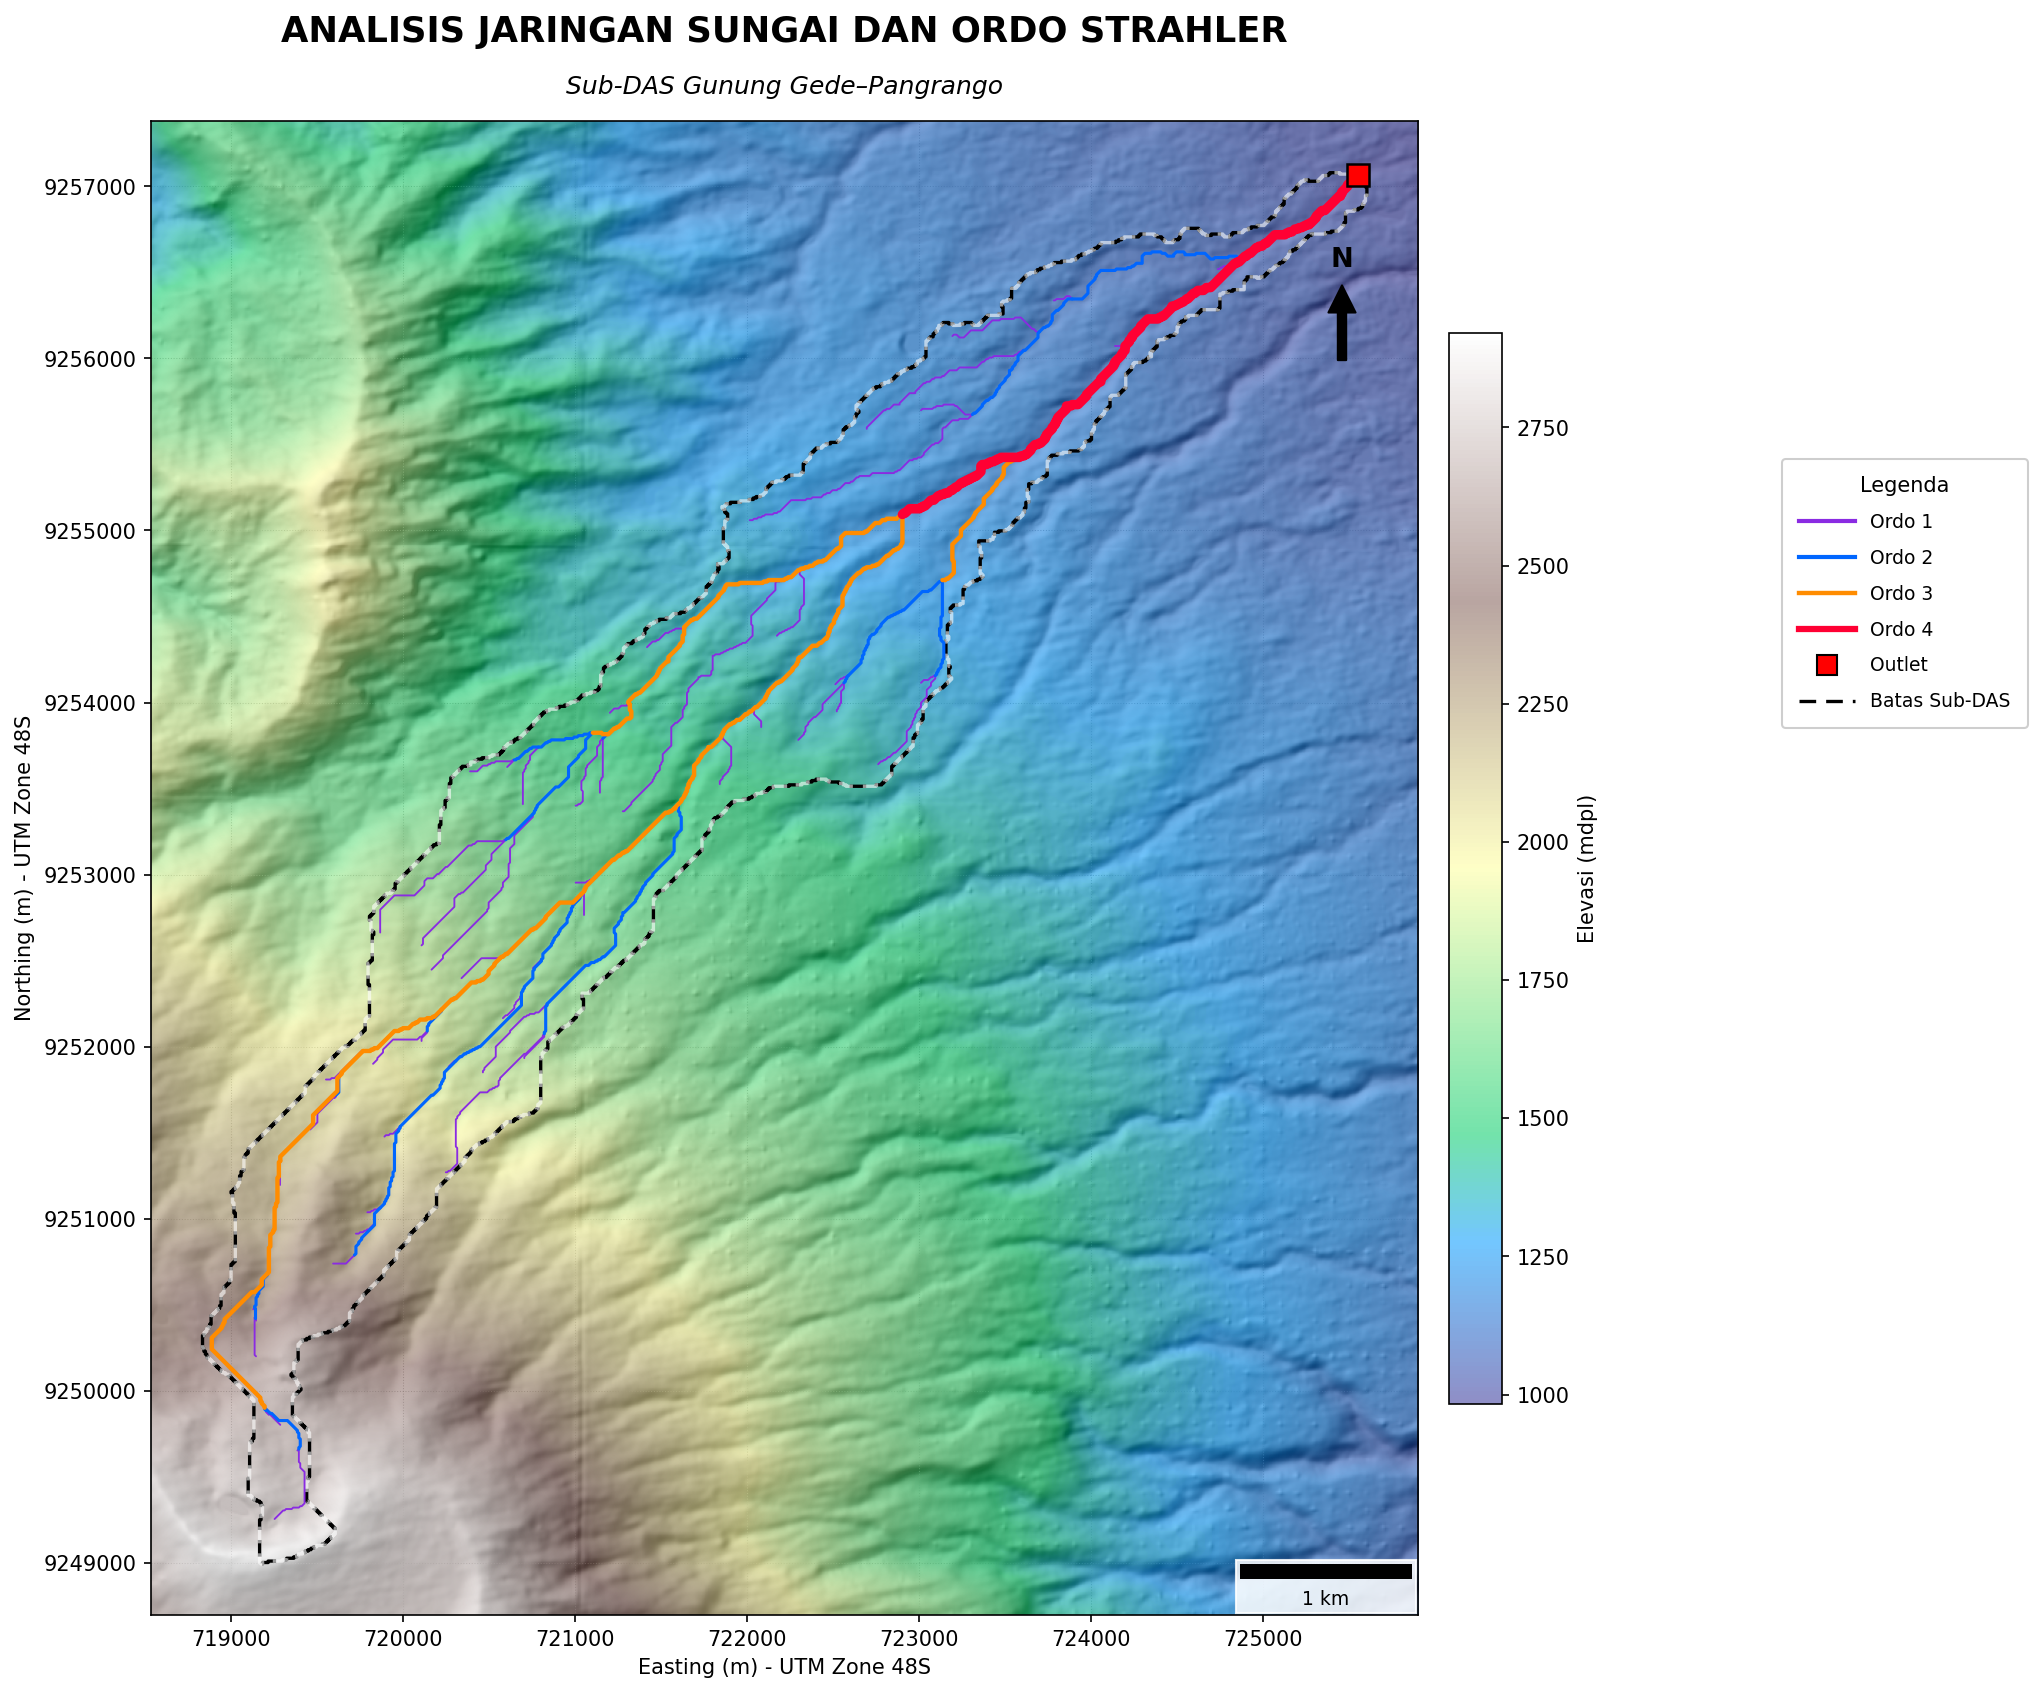


Peta final berhasil dirender. Lihat sel export (Tahap 17) untuk menyimpan ke PNG/PDF.


In [ ]:
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.lines import Line2D


BASE_ORDER_STYLE = {
    1: {"color": "#8A2BE2", "lw": 0.9},   # Ungu / Blue Violet
    2: {"color": "#0066FF", "lw": 1.5},   # Biru terang
    3: {"color": "#FF8C00", "lw": 2.1},   # Oranye
    4: {"color": "#FF0033", "lw": 3.0},   # Merah terang
}

EXTRA_COLORS = [
    "#FF1493",   # Pink
    "#800080",   # Ungu tua
    "#000000",   # Hitam
    "#8B4513",   # Cokelat
]


def order_style(o):

    if o in BASE_ORDER_STYLE:
        return BASE_ORDER_STYLE[o]

    extra_idx = (o - 5) % len(EXTRA_COLORS)

    return {
        "color": EXTRA_COLORS[extra_idx],
        "lw": 3.0 + 0.5 * (o - 4)
    }

buffer_m = 300

minx, miny, maxx, maxy = subdas_gdf.total_bounds

minx -= buffer_m
miny -= buffer_m
maxx += buffer_m
maxy += buffer_m


with rasterio.open(DEM_FILLED_PATH) as src:

    win = rasterio.windows.from_bounds(
        minx,
        miny,
        maxx,
        maxy,
        transform=src.transform
    )

    dem_win = src.read(
        1,
        window=win
    )

    dem_win_transform = src.window_transform(win)

    dem_win_extent = rasterio.transform.array_bounds(
        dem_win.shape[0],
        dem_win.shape[1],
        dem_win_transform
    )


with rasterio.open(HILLSHADE_PATH) as src:

    win_hs = rasterio.windows.from_bounds(
        minx,
        miny,
        maxx,
        maxy,
        transform=src.transform
    )

    hs_win = src.read(
        1,
        window=win_hs
    )


dem_win_masked = np.where(
    dem_win == DST_NODATA,
    np.nan,
    dem_win
)

hs_win_masked = np.where(
    np.isnan(dem_win_masked),
    np.nan,
    hs_win
)


extent = (
    dem_win_extent[0],
    dem_win_extent[2],
    dem_win_extent[1],
    dem_win_extent[3]
)

fig, ax = plt.subplots(
    figsize=(15, 12),
    dpi=150
)

ax.imshow(
    hs_win_masked,
    cmap="gray",
    extent=extent,
    origin="upper",
    zorder=1
)

im_dem = ax.imshow(
    dem_win_masked,
    cmap="terrain",
    extent=extent,
    origin="upper",
    alpha=0.55,
    zorder=2
)

subdas_gdf.boundary.plot(
    ax=ax,
    color="black",
    linestyle=(0, (5, 3)),
    linewidth=1.6,
    zorder=5
)

subdas_gdf.boundary.plot(
    ax=ax,
    color="white",
    linestyle=(4, (5, 3)),
    linewidth=1.6,
    alpha=0.6,
    zorder=5
)

orders_present = sorted(
    streams_in_subdas["orde"].unique().tolist()
)

legend_handles = []


for o in orders_present:

    style = order_style(o)

    subset = streams_in_subdas[
        streams_in_subdas["orde"] == o
    ]

    subset.plot(
        ax=ax,
        color=style["color"],
        linewidth=style["lw"],
        zorder=6 + o,
        capstyle="round"
    )

    # Masukkan hanya ORDO ke legenda
    legend_handles.append(
        Line2D(
            [0],
            [0],
            color=style["color"],
            lw=max(style["lw"], 2.0),
            label=f"Ordo {o}"
        )
    )

main_stream_gdf.plot(
    ax=ax,
    color="#FF0033",
    linewidth=order_style(ORDE_MAKS_SUBDAS)["lw"] + 1.6,
    zorder=6 + ORDE_MAKS_SUBDAS + 1,
    capstyle="round"
)

ax.plot(
    outlet_snapped_pt.x,
    outlet_snapped_pt.y,

    marker="s",
    markersize=11,

    markerfacecolor="red",
    markeredgecolor="black",
    markeredgewidth=1.2,

    zorder=23
)


# Outlet untuk legenda
legend_handles.append(
    Line2D(
        [0],
        [0],
        marker="s",
        color="w",
        markerfacecolor="red",
        markeredgecolor="black",
        markersize=10,
        label="Outlet"
    )
)

legend_handles.append(
    Line2D(
        [0],
        [0],
        color="black",
        linestyle=(0, (5, 3)),
        lw=1.6,
        label="Batas Sub-DAS"
    )
)

ax.set_title(
    "ANALISIS JARINGAN SUNGAI DAN ORDO STRAHLER",
    fontsize=17,
    fontweight="bold",
    pad=38
)


ax.text(
    0.5,
    1.015,

    "Sub-DAS Gunung Gede–Pangrango",

    transform=ax.transAxes,

    ha="center",
    va="bottom",

    fontsize=12,
    style="italic"
)

ax.grid(
    True,
    which="major",

    color="gray",
    linestyle=":",
    linewidth=0.5,
    alpha=0.6,

    zorder=0.5
)

ax.set_xlabel(
    "Easting (m) - UTM Zone 48S"
)

ax.set_ylabel(
    "Northing (m) - UTM Zone 48S"
)

ax.ticklabel_format(
    style="plain"
)


ax.set_xlim(
    extent[0],
    extent[1]
)

ax.set_ylim(
    extent[2],
    extent[3]
)

ax.set_aspect(
    "equal"
)


cbar = fig.colorbar(
    im_dem,
    ax=ax,

    fraction=0.035,
    pad=0.02
)

cbar.set_label(
    "Elevasi (mdpl)",
    fontsize=10
)

leg = ax.legend(
    handles=legend_handles,

    loc="upper left",

    bbox_to_anchor=(1.28, 0.78),

    fontsize=9,

    framealpha=0.95,

    title="Legenda",
    title_fontsize=10,

    ncol=1,

    borderpad=0.9,

    labelspacing=0.9,

    handlelength=3.0
)

leg.set_zorder(30)

ax_w = extent[1] - extent[0]
ax_h = extent[3] - extent[2]

arrow_x = extent[1] - 0.06 * ax_w
arrow_y = extent[3] - 0.16 * ax_h

arrow_len = 0.05 * ax_h


ax.annotate(
    "N",

    xy=(
        arrow_x,
        arrow_y + arrow_len * 1.25
    ),

    ha="center",

    fontsize=13,
    fontweight="bold",

    zorder=30
)


ax.annotate(
    "",

    xy=(
        arrow_x,
        arrow_y + arrow_len
    ),

    xytext=(
        arrow_x,
        arrow_y
    ),

    arrowprops=dict(
        facecolor="black",
        edgecolor="black",

        width=4,
        headwidth=13,
        headlength=13
    ),

    zorder=30
)

scalebar = ScaleBar(
    1,

    units="m",

    location="lower right",

    box_alpha=0.85,

    font_properties={
        "size": 9
    }
)

ax.add_artist(
    scalebar
)

plt.subplots_adjust(
    left=0.08,
    right=0.76,
    top=0.91,
    bottom=0.08
)

plt.show()


print(
    "\nPeta final berhasil dirender."
    " Lihat sel export (Tahap 17) untuk menyimpan ke PNG/PDF."
)

## TAHAP 17 — Export Peta (PNG 400 dpi & PDF) dan Data Vektor

Menyimpan peta akhir dan seluruh data vektor hasil analisis. Setiap file divalidasi keberadaannya setelah disimpan.

In [ ]:

PNG_PATH = DIR_MAPS / "Peta_SubDAS_Strahler_Gede_Pangrango.png"
PDF_PATH = DIR_MAPS / "Peta_SubDAS_Strahler_Gede_Pangrango.pdf"

fig.savefig(PNG_PATH, dpi=400, bbox_inches="tight", facecolor="white")
check_file_exists(PNG_PATH, label="Peta PNG")
print(f"[OK] PNG tersimpan: {PNG_PATH} ({PNG_PATH.stat().st_size:,} bytes)")

fig.savefig(PDF_PATH, bbox_inches="tight", facecolor="white")
check_file_exists(PDF_PATH, label="Peta PDF")
print(f"[OK] PDF tersimpan: {PDF_PATH} ({PDF_PATH.stat().st_size:,} bytes)")

# --- Export vektor tambahan (outlet final) ---
OUTLET_GPKG_PATH = DIR_VECTOR / "Outlet.gpkg"
outlet_final_gdf = gpd.GeoDataFrame(
    {"nama": ["Outlet Sub-DAS"], "x": [outlet_snapped_pt.x], "y": [outlet_snapped_pt.y],
     "outlet_mode": [OUTLET_MODE]},
    geometry=[outlet_snapped_pt], crs=DST_CRS,
)
outlet_final_gdf.to_file(OUTLET_GPKG_PATH, driver="GPKG")
validate_vector(OUTLET_GPKG_PATH, label="Outlet (GPKG final)")

print("\nSeluruh file vector hasil analisis (06_vector/):")
for f in sorted(DIR_VECTOR.glob("*.gpkg")):
    print(f"  - {f.name}  ({f.stat().st_size:,} bytes)")

print("\nSeluruh file raster hasil analisis:")
for d in [DIR_PRE, DIR_HYDRO, DIR_STREAMS, DIR_WATERSHED]:
    for f in sorted(d.glob("*.tif")):
        print(f"  - {f.relative_to(OUT_ROOT)}  ({f.stat().st_size:,} bytes)")


TAHAP 17 — EXPORT
[OK] PNG tersimpan: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\05_maps\Peta_SubDAS_Strahler_Gede_Pangrango.png (2,691,134 bytes)
[OK] PDF tersimpan: C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\05_maps\Peta_SubDAS_Strahler_Gede_Pangrango.pdf (2,168,171 bytes)
  [VALID VECTOR] Outlet (GPKG final): 1 feature(s), crs=EPSG:32748, geom_type=['Point']

Seluruh file vector hasil analisis (06_vector/):
  - Jaringan_Sungai_Strahler.gpkg  (143,360 bytes)
  - Outlet.gpkg  (98,304 bytes)
  - SubDAS_Gede_Pangrango.gpkg  (135,168 bytes)

Seluruh file raster hasil analisis:
  - 01_preprocessing\DEM_Gede_Pangrango_UTM48S.tif  (78,886,334 bytes)
  - 02_hydrology\dem_filled.tif  (150,637,884 bytes)
  - 02_hydrology\flow_accumulation.tif  (75,337,902 bytes)
  - 02_hydrology\flow_direction.tif  (37,687,910 bytes)
  - 03_streams\stream_order.tif  (75,337,902 bytes)
  - 03_streams\streams.tif  (75,337,902 bytes)
  - 04_watershed\dem_subdas.tif  (6,371,028 bytes)
  - 04_watershed\

## TAHAP 18 — Tabel Statistik Akhir

In [ ]:

# --- Panjang sungai total & per orde (dihitung dari geometri vector aktual) ---
streams_in_subdas["panjang_km"] = streams_in_subdas.geometry.length / 1000.0
total_length_km = float(streams_in_subdas["panjang_km"].sum())

length_by_order = (
    streams_in_subdas.groupby("orde")["panjang_km"].sum().reset_index()
    .rename(columns={"orde": "Orde", "panjang_km": "Panjang Sungai (km)"})
    .sort_values("Orde")
)
length_by_order["Panjang Sungai (km)"] = length_by_order["Panjang Sungai (km)"].round(3)

summary_table = pd.DataFrame({
    "Parameter": [
        "Luas Sub-DAS", "Luas Sub-DAS", "Perimeter",
        "Elevasi minimum", "Elevasi maksimum", "Elevasi rata-rata",
        "Orde maksimum", "Total panjang sungai", "Jumlah confluence berlabel",
        "Outlet (X, Y - UTM 48S)", "Metode pemilihan outlet",
    ],
    "Nilai": [
        f"{area_ha:,.2f} ha", f"{area_km2:,.3f} km2", f"{perim_km:,.2f} km",
        f"{elev_min:.1f} mdpl", f"{elev_max:.1f} mdpl", f"{elev_mean:.1f} mdpl",
        f"{ORDE_MAKS_SUBDAS}", f"{total_length_km:,.2f} km", f"{len(confluence_gdf)}",
        f"({outlet_snapped_pt.x:.1f}, {outlet_snapped_pt.y:.1f})", OUTLET_MODE,
    ],
})

print("\n=== TABEL PARAMETER UTAMA ===")
print(summary_table.to_string(index=False))

print("\n=== PANJANG SUNGAI PER ORDE ===")
print(length_by_order.to_string(index=False))

STATS_CSV_PATH = DIR_MAPS / "statistik_subdas.csv"
summary_table.to_csv(STATS_CSV_PATH, index=False)
length_csv_path = DIR_MAPS / "panjang_sungai_per_orde.csv"
length_by_order.to_csv(length_csv_path, index=False)
check_file_exists(STATS_CSV_PATH, label="Statistik CSV")
check_file_exists(length_csv_path, label="Panjang sungai per orde CSV")
print(f"\nTabel statistik disimpan ke:\n  - {STATS_CSV_PATH}\n  - {length_csv_path}")


TAHAP 18 — STATISTIK

=== TABEL PARAMETER UTAMA ===
                 Parameter                 Nilai
              Luas Sub-DAS           1,000.00 ha
              Luas Sub-DAS            10.000 km2
                 Perimeter              31.41 km
           Elevasi minimum            999.0 mdpl
          Elevasi maksimum           2921.6 mdpl
         Elevasi rata-rata           1597.3 mdpl
             Orde maksimum                     4
      Total panjang sungai              43.46 km
Jumlah confluence berlabel                     5
   Outlet (X, Y - UTM 48S) (725549.6, 9257067.5)
   Metode pemilihan outlet                  auto

=== PANJANG SUNGAI PER ORDE ===
 Orde  Panjang Sungai (km)
    1               18.559
    2               10.434
    3               10.850
    4                3.620

Tabel statistik disimpan ke:
  - C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\05_maps\statistik_subdas.csv
  - C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\05_maps\panjang_sungai_per_

## TAHAP 19 — Final Validation (Self-Check)

Memeriksa ulang seluruh output wajib. Jika ada yang gagal/hilang, notebook akan melaporkan dengan jelas tahap mana yang bermasalah alih-alih menyatakan sukses secara keliru.

In [ ]:
checklist = [
    ("DEM input", DEM_PATH),
    ("DEM UTM", DEM_UTM_PATH),
    ("DEM filled", DEM_FILLED_PATH),
    ("Flow direction", FLOW_DIR_PATH),
    ("Flow accumulation", FLOW_ACC_PATH),
    ("Streams (raster)", STREAMS_PATH),
    ("Stream order (raster)", STREAM_ORDER_PATH),
    ("Watershed (raster)", WATERSHED_RASTER_PATH),
    ("DEM Sub-DAS (clipped)", DEM_SUBDAS_PATH),
    ("Hillshade", HILLSHADE_PATH),
    ("Sub-DAS vector (GPKG)", SUBDAS_GPKG_PATH),
    ("Stream vector Strahler (GPKG)", STREAMS_STRAHLER_GPKG),
    ("Outlet vector (GPKG)", OUTLET_GPKG_PATH),
    ("Peta Final PNG", PNG_PATH),
    ("Peta Final PDF", PDF_PATH),
]

results = []
all_ok = True
for name, path in checklist:
    p = Path(path)
    ok = p.exists() and p.stat().st_size > 0
    results.append((name, p, ok))
    if not ok:
        all_ok = False
    mark = "[v]" if ok else "[x]"
    print(f"{mark} {name:35s} -> {p}")

print()
if all_ok:
    print("=" * 40)
    print("ANALISIS BERHASIL")
    print("SEMUA OUTPUT VALID")
    print("=" * 40)
else:
    print("=" * 40)
    print("ANALISIS GAGAL")
    print("=" * 40)
    print("\nTahap/file yang gagal:")
    for name, p, ok in results:
        if not ok:
            print(f"  - {name}: {p} (tidak ditemukan / kosong)")
    raise RuntimeError("Final validation gagal -- lihat daftar file yang bermasalah di atas.")

print(f"\nRingkasan akhir:")
print(f"  Sub-DAS         : {area_ha:,.1f} ha ({area_km2:,.2f} km2)")
print(f"  Orde maksimum   : {ORDE_MAKS_SUBDAS}")
print(f"  Panjang sungai  : {total_length_km:,.2f} km")
print(f"  Peta PNG (400dpi): {PNG_PATH}")
print(f"  Peta PDF         : {PDF_PATH}")


TAHAP 19 — FINAL VALIDATION
[v] DEM input                           -> C:\anhid\Tugas kuliah2\python\DEM_Gede_Pangrango_Clip.tif
[v] DEM UTM                             -> C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\01_preprocessing\DEM_Gede_Pangrango_UTM48S.tif
[v] DEM filled                          -> C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\dem_filled.tif
[v] Flow direction                      -> C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\flow_direction.tif
[v] Flow accumulation                   -> C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\02_hydrology\flow_accumulation.tif
[v] Streams (raster)                    -> C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\03_streams\streams.tif
[v] Stream order (raster)               -> C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\03_streams\stream_order.tif
[v] Watershed (raster)                  -> C:\anhid\Tugas kuliah2\python\HASIL_ANALISIS_DAS\04_watershed\watershed.tif
[v] DEM